# Lab 01 — Feature engineering and feature selection

*Check the tools, understand the data, build features, and choose among them*

**Goal.** Confirm that the course environment works, read a dataset's data card before its rows, engineer features and encode them inside a leakage-safe pipeline, see why scaling changes distance, and select features without letting the answer leak in.

**Data.** `all_datasets/supervised/hotel_bookings/hotel_bookings.zip` with its data card `README.md`, `all_datasets/supervised/telco_customer_churn/telco_customer_churn.csv`, `all_datasets/supervised/bank_marketing/bank_marketing.csv`

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab01_features/lab01_features_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab01_features/lab01_features_worked.py`.

**Evidence.** `results/lab01/` — environment versions, missing-value shares, cancellation by days booked ahead, nearest neighbors before and after scaling, feature-set comparison, L1 coefficients

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Check your versions, read the data card, find the gaps and the column that leaks the outcome | 2–4 |
| B | Engineer five columns from the hotel bookings and test them on a model | 5–7 |
| C | Repair the Telco columns and see how scaling changes a customer's neighbors | 8–9 |
| D | Select features for the bank's call list without leaking the outcome | 10–12 |
| Finish | Save the evidence; then add the arrival weekday yourself | 13–15 |
| After | Your-turn tasks, expected findings, troubleshooting and the two checklists (on the lab sheet) | — |

## Setup

Imports and paths. `start_lab()`, from `all_experiments/course_setup.py`, finds the course folder by looking upward for `all_datasets/`; figures and tables go to `results/lab01/`.

### Question 1 — Setup

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The libraries this lab uses.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer                      # different steps for number and text columns
from sklearn.feature_selection import SelectKBest, f_classif       # keep the k strongest columns
from sklearn.impute import SimpleImputer                           # fill missing values
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline                              # chain preparation and model into one object
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 3. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab01")

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab01/ and models/


## Part A — Environment check and a first look at the data

**Goal.** Confirm your setup, then learn what each booking column means and which one was written after the outcome.

*Questions 2–4 · Data: hotel bookings and their data card*

### Question 2 — Print the package versions

Every result in this course depends on four packages. Print their versions once, at the top, so that if a number ever changes between two runs you can rule out the environment first.

In [2]:
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.3.5
pandas: 2.3.3
Matplotlib: 3.10.6
scikit-learn: 1.7.2


### Question 3 — Read the data card, then the bookings

The hotel table has one row for each of 119,390 bookings at two Portuguese hotels, and `is_canceled` is 1 if the booking was cancelled. Every dataset in this course comes with a data card, the `README.md` beside it, and a professional reads that first: it says what each column means, in which units, and how it was recorded. Then answer three questions from the table itself: how big is it, which hotels and dates does it cover, and how balanced is the label? The arrival date is spread over three columns, so the cell joins them into one.

In [3]:
# The data card beside the data says what each column means. Its column table starts at "| `hotel`".
card = (DATA / "supervised/hotel_bookings/README.md").read_text(encoding="utf-8")
for row in card[card.index("| `hotel`"):].splitlines():
    column, meaning = row.split(" | ")[:2]
    print(f"{column.strip('| `'):32s}{meaning}")

# The bookings themselves: one row per booking.
hotels = pd.read_csv(DATA / "supervised/hotel_bookings/hotel_bookings.zip")
print("\nshape:", hotels.shape)
print(hotels["hotel"].value_counts().to_string())

# The arrival date is spread over three columns, with the month as a word: join them into one date.
text_date = (hotels["arrival_date_year"].astype(str) + "-" + hotels["arrival_date_month"]
             + "-" + hotels["arrival_date_day_of_month"].astype(str))
hotels["arrival_date"] = pd.to_datetime(text_date, format="%Y-%B-%d")
print("arrivals from", hotels["arrival_date"].min().date(), "to", hotels["arrival_date"].max().date())

print("\nCancellation rate:\n", hotels["is_canceled"].value_counts(normalize=True).round(3))

hotel                           `Resort Hotel` (Algarve) or `City Hotel` (Lisbon)
is_canceled                     1 if the booking was cancelled: the label
lead_time                       days from making the booking to the arrival date
arrival_date_year               year of arrival
arrival_date_month              month of arrival, as a word
arrival_date_week_number        week of the year of arrival
arrival_date_day_of_month       day of the month of arrival
stays_in_weekend_nights         Saturday and Sunday nights booked
stays_in_week_nights            Monday to Friday nights booked
adults                          adults on the booking
children                        children on the booking
babies                          babies on the booking
meal                            board booked: `BB` bed and breakfast, `HB` half board, `FB` full board, `SC` or `Undefined` none
country                         guest's country, as a three-letter ISO code
market_segment                  where

arrivals from 2015-07-01 to 2017-08-31

Cancellation rate:
 is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


### Question 4 — Chart the missing values, and date the columns

A bar chart makes the gaps easier to compare than a column of numbers. Then ask when each column was filled in. `reservation_status` says how the booking ended, so check whether it already knows who cancelled, and compare the date it was written with the arrival date.

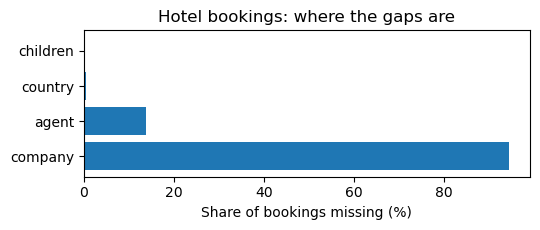

company     94.31
agent       13.69
country      0.41
children     0.00

 is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207

 is_canceled                             0      1
status written on or after arrival              
False                                   0  42137
True                                75166   2087


In [4]:
# Share of bookings missing each column, largest first; columns with no gaps are left out.
missing = hotels.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]

plt.figure(figsize=(5.5, 2.4))
plt.barh(missing.index, missing.values * 100)
plt.xlabel("Share of bookings missing (%)")
plt.title("Hotel bookings: where the gaps are")
plt.tight_layout()
plt.savefig(RESULTS / "hotel_where_the_gaps_are.png", dpi=160, bbox_inches="tight")
plt.show()
print(missing.mul(100).round(2).to_string())

# reservation_status says how the booking ended. Does it already know the answer?
print("\n", pd.crosstab(hotels["reservation_status"], hotels["is_canceled"]))

# And when was it written? Compare its date with the arrival date.
status_date = pd.to_datetime(hotels["reservation_status_date"])
written_on_or_after_arrival = (status_date >= hotels["arrival_date"]).rename("status written on or after arrival")
print("\n", pd.crosstab(written_on_or_after_arrival, hotels["is_canceled"]))

**What the output shows.** All four packages import cleanly. 119,390 bookings and 32 columns: 79,330 at the city hotel and 40,060 at the resort, for arrivals from 1 July 2015 to 31 August 2017. 37.0% were cancelled, so always answering *not cancelled* is already 63.0% accurate. `company` is empty for 94.3% of bookings and `agent` for 13.7%; the data's authors call these *not applicable*, because no company or agent was involved, so here a blank is information rather than a gap. `country` is missing for 0.4% of bookings and `children` for 4. `reservation_status` is the answer in disguise: every `Canceled` and `No-Show` booking has `is_canceled` 1, and every `Check-Out` has 0. All 75,166 kept bookings had their status written on or after arrival, and 42,137 of the 44,224 cancelled ones before it. The column stays in the table as a record but never enters a model.

**Checkpoint: before you move on**

- Your package versions print, and you know which ones differ from the sheet's.
- 119,390 bookings, 37.0% of them cancelled, so always guessing “not cancelled” is already 63.0% accurate.
- You can say why `reservation_status` must never be a feature.

## Part B — Feature engineering

**Goal.** Turn nights, guests, lead time and booking history into five new columns, and measure whether they help a model.

*Questions 5–7 · Data: hotel bookings*

### Question 5 — Engineer five new columns

Feature engineering means building inputs the model cannot see on its own. `total_nights` adds the weekend and week nights, `total_guests` adds the adults, children and babies, and `with_children` flags a family; the four blank `children` counts are read as none. `log_lead_time` takes $\ln(1+x)$ of the days booked ahead, because a few bookings were made up to two years early and would otherwise stretch the scale. `cancelled_before` flags a customer who has cancelled a booking before. Every new column uses only what was known when the booking was made, which is the test each feature must pass.

In [5]:
# 1. Length of stay: weekend nights plus week nights.
hotels["total_nights"] = hotels["stays_in_weekend_nights"] + hotels["stays_in_week_nights"]

# 2-3. Size of the party, and whether children or babies come along.
#      Four bookings have no children count: a blank is read as none.
children = hotels["children"].fillna(0).astype(int)
hotels["total_guests"] = hotels["adults"] + children + hotels["babies"]
hotels["with_children"] = ((children + hotels["babies"]) > 0).astype(int)

# 4. Lead time is skewed: most bookings are made weeks ahead, a few up to two years ahead.
#    ln(1 + days) spreads the short lead times and squeezes the long ones.
hotels["log_lead_time"] = np.log1p(hotels["lead_time"])

# 5. Has this customer cancelled a booking before?
hotels["cancelled_before"] = (hotels["previous_cancellations"] > 0).astype(int)

new = ["total_nights", "total_guests", "with_children", "log_lead_time", "cancelled_before"]
inputs = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
          "previous_cancellations"]
two_bookings = [14876, 40060]                # a family at the resort hotel; the first city-hotel booking
print(hotels.loc[two_bookings, ["hotel"] + inputs + new].round(3).T.to_string())

                                14876       40060
hotel                    Resort Hotel  City Hotel
lead_time                         132           6
stays_in_weekend_nights             2           0
stays_in_week_nights                4           2
adults                              2           1
children                          0.0         0.0
babies                              1           0
previous_cancellations              1           0
total_nights                        6           2
total_guests                        3           1
with_children                       1           0
log_lead_time                    4.89       1.946
cancelled_before                    1           0


### Question 6 — Check the new columns for signal

Grouping the label by the new columns shows whether they carry signal. Lead time is cut into bands of days, and stays of eight nights or more share one bar.

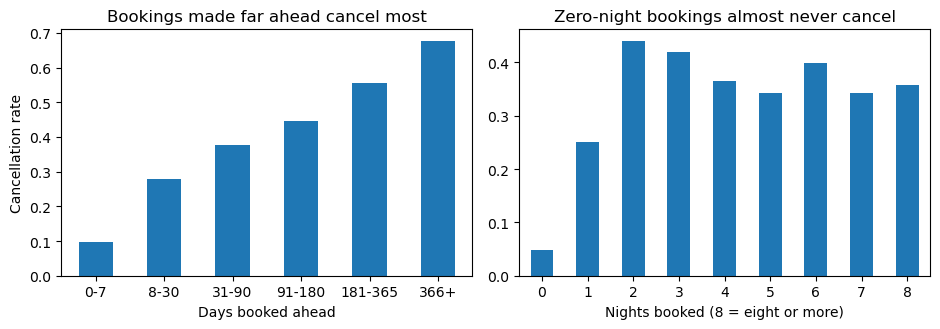

by days ahead:     {'0-7': 0.096, '8-30': 0.279, '31-90': 0.377, '91-180': 0.447, '181-365': 0.555, '366+': 0.677}
by nights:         {0: 0.049, 1: 0.251, 2: 0.44, 3: 0.419, 4: 0.366, 5: 0.342, 6: 0.398, 7: 0.343, 8: 0.357}
with children:     {0: 0.372, 1: 0.349}
cancelled before:  {0: 0.339, 1: 0.916}


In [6]:
# Cancellation rate by how far ahead the booking was made, and by the length of the stay.
lead_band = pd.cut(hotels["lead_time"], [-1, 7, 30, 90, 180, 365, 800],
                   labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"])
by_lead = hotels.groupby(lead_band, observed=True)["is_canceled"].mean()
by_nights = hotels.groupby(hotels["total_nights"].clip(upper=8))["is_canceled"].mean()   # 8 means 8 or more

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
by_lead.plot.bar(ax=axes[0], rot=0)
axes[0].set_xlabel("Days booked ahead")
axes[0].set_ylabel("Cancellation rate")
axes[0].set_title("Bookings made far ahead cancel most")
by_nights.plot.bar(ax=axes[1], rot=0)
axes[1].set_xlabel("Nights booked (8 = eight or more)")
axes[1].set_title("Zero-night bookings almost never cancel")
plt.tight_layout()
plt.savefig(RESULTS / "far_ahead_bookings_cancel_most.png", dpi=160, bbox_inches="tight")
plt.show()

print("by days ahead:    ", by_lead.round(3).to_dict())
print("by nights:        ", by_nights.round(3).to_dict())
print("with children:    ", hotels.groupby("with_children")["is_canceled"].mean().round(3).to_dict())
print("cancelled before: ", hotels.groupby("cancelled_before")["is_canceled"].mean().round(3).to_dict())

### Question 7 — Test the new columns on a model

Does the engineering help a model? The only fair test is the same model and the same split, with and without the new columns. The raw set takes eleven numbers and five categories known when the booking is made. It leaves out the agent and company IDs (codes with over 300 values each), the arrival date columns, which Lab 2 puts to work, and columns that may have been filled in later: the country, the room actually assigned and the number of changes. Your-turn task 1 tests two of them. Preprocessing lives inside a pipeline: imputation, scaling and encoding are learned from the training rows only, and reapplied unchanged to validation rows.

In [7]:
def make_preprocess(num_cols, cat_cols):
    """Prepare a table for a model: fill and scale the number columns, fill and one-hot encode the text columns."""
    numbers = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categories = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([("num", numbers, num_cols), ("cat", categories, cat_cols)])

y = hotels["is_canceled"]
raw_num = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
           "previous_cancellations", "previous_bookings_not_canceled", "adr",
           "required_car_parking_spaces", "total_of_special_requests"]
raw_cat = ["hotel", "meal", "market_segment", "deposit_type", "customer_type"]
feature_sets = {
    "raw columns": (raw_num, raw_cat),
    "raw + engineered": (raw_num + new, raw_cat),
}

# The same split and the same model for both sets, so only the columns differ.
for name, (num_cols, cat_cols) in feature_sets.items():
    X = hotels[num_cols + cat_cols]
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
    model = Pipeline([
        ("preprocess", make_preprocess(num_cols, cat_cols)),
        ("model", LogisticRegression(max_iter=3000)),
    ])
    model.fit(X_train, y_train)
    auc = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
    print(f"{name:18s} validation ROC AUC = {auc:.3f}")
print("validation bookings:", len(y_valid))

raw columns        validation ROC AUC = 0.846


raw + engineered   validation ROC AUC = 0.855
validation bookings: 29848


**What the output shows.** Booking 14876, a family at the resort hotel, was made 132 days ahead for 2 weekend and 4 week nights, with 2 adults and a baby, by a customer who had cancelled once before: 6 nights, 3 guests, `with_children` 1, `log_lead_time` $\ln 133 = 4.89$ and `cancelled_before` 1. Cancellations climb with lead time, from 9.6% for bookings made within a week to 67.7% for those made more than a year ahead, and customers who had cancelled before cancelled again 91.6% of the time, against 33.9%. Zero-night bookings almost never cancel (4.9%), while families cancel about as often as everyone else (34.9% against 37.2%). Fed to the same logistic regression on the same split, the engineered columns lift validation ROC AUC from 0.846 to 0.855: a real but modest gain, from better columns and no new model.

**Checkpoint: before you move on**

- Validation ROC AUC rises from 0.846 with the raw columns to 0.855 with the engineered ones.
- You can explain why `log_lead_time` suits a linear model better than the raw lead time.

## Part C — Scaling changes the geometry

**Goal.** Repair a number column stored as text, then see how scaling changes which customers count as neighbors.

*Questions 8–9 · Data: Telco customer churn*

### Question 8 — Fix the types, then see the units

The Telco churn table has one row per customer of a phone and internet company, and `Churn` says whether they left. Before any distance can be measured, the numbers have to be numbers: `TotalCharges` arrives as text. Find the cells that will not convert, see whose they are, and repair them with a rule you can defend. Then compare the units of the three time-and-money columns.

In [8]:
churn = pd.read_csv(DATA / "supervised/telco_customer_churn/telco_customer_churn.csv")
print("shape:", churn.shape, " TotalCharges is stored as:", churn["TotalCharges"].dtype)

# Convert the text to numbers; anything that is not a number becomes NaN, so it can be found.
total = pd.to_numeric(churn["TotalCharges"], errors="coerce")
not_numbers = total.isna()
print("rows that are not numbers:", not_numbers.sum(),
      " their tenure:", churn.loc[not_numbers, "tenure"].unique())
churn["TotalCharges"] = total.fillna(0)      # brand-new customers: nothing billed yet

money = ["tenure", "MonthlyCharges", "TotalCharges"]
print(churn[money].describe().loc[["mean", "std"]].round(2))

shape: (7043, 21)  TotalCharges is stored as: object
rows that are not numbers: 11  their tenure: [0]
      tenure  MonthlyCharges  TotalCharges
mean   32.37           64.76       2279.73
std    24.56           30.09       2266.79


### Question 9 — Compare neighbors before and after scaling

Many models (nearest neighbors, clustering, SVMs, neural networks) work by measuring distances between rows. Take one customer, 7795-CFOCW, with 45 months of tenure at $42.30 a month, and find the ten customers closest to them twice: once in raw units, and once after standardizing each column to mean 0 and standard deviation 1.

raw units     tenure 29-49 months   monthly $39.20-60.20   total $1,815-1,861
standardized  tenure 43-47 months   monthly $38.25-45.55   total $1,755-2,065
customers in both lists: 1


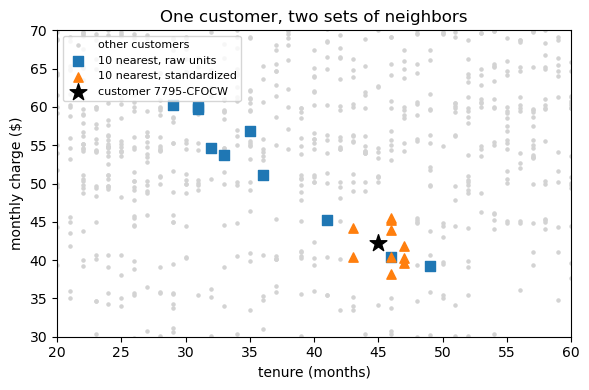

In [9]:
X_raw = churn[money].to_numpy()
X_std = StandardScaler().fit_transform(X_raw)          # every column now has mean 0 and standard deviation 1

def neighbors(X, row, k=10):
    """The k rows of X closest to `row`, not counting the row itself."""
    finder = NearestNeighbors(n_neighbors=k + 1).fit(X)
    found = finder.kneighbors(X[[row]], return_distance=False)[0]
    return found[found != row][:k]

customer = 3                                 # 7795-CFOCW: 45 months at $42.30 a month
near_raw = neighbors(X_raw, customer)
near_std = neighbors(X_std, customer)
for label, rows in [("raw units", near_raw), ("standardized", near_std)]:
    n = churn.loc[rows]
    print(f"{label:12s}  tenure {n.tenure.min()}-{n.tenure.max()} months   "
          f"monthly ${n.MonthlyCharges.min():.2f}-{n.MonthlyCharges.max():.2f}   "
          f"total ${n.TotalCharges.min():,.0f}-{n.TotalCharges.max():,.0f}")
print("customers in both lists:", len(set(near_raw) & set(near_std)))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(churn["tenure"], churn["MonthlyCharges"], s=5, color="lightgrey", label="other customers")
ax.scatter(X_raw[near_raw, 0], X_raw[near_raw, 1], s=45, marker="s", label="10 nearest, raw units")
ax.scatter(X_raw[near_std, 0], X_raw[near_std, 1], s=45, marker="^", label="10 nearest, standardized")
ax.scatter(X_raw[customer, 0], X_raw[customer, 1], s=160, marker="*", color="black", label="customer 7795-CFOCW")
ax.set_xlim(20, 60)
ax.set_ylim(30, 70)
ax.set_xlabel("tenure (months)")
ax.set_ylabel("monthly charge ($)")
ax.set_title("One customer, two sets of neighbors")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS / "one_customer_two_sets_of_neighbors.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** `TotalCharges` is text because 11 cells hold a blank, and all 11 belong to customers with `tenure` 0, who have not been billed yet, so 0 is the right repair, not the mean. Its standard deviation is 2,266.79 dollars against 24.56 months for `tenure`, so in raw units a distance is almost entirely a difference in total bill. The ten raw neighbors have paid between $1,815 and $1,861, close to the customer's $1,841, but they span 29 to 49 months and $39.20 to $60.20 a month. After scaling they span 43 to 47 months and $38.25 to $45.55: customers who really do look alike. Only one customer is in both lists. Nothing about the customers changed, only the measuring stick, which is why the scaler sits inside the pipeline.

**Checkpoint: before you move on**

- `TotalCharges` had 11 blank cells, all from first-month customers, so zero is the right repair.
- The ten nearest neighbors in raw units and after scaling share only one customer.

## Part D — Feature selection without leakage

**Goal.** Choose features for a bank's call list using only what is known before the call.

*Questions 10–12 · Data: bank marketing calls*

### Question 10 — Define the bank-call task

The bank-marketing table records 41,188 phone calls from a Portuguese bank's campaigns to sell a term deposit, and `y` says whether the customer signed up. The file separates its fields with semicolons, a common European format. The task is to decide *before dialing* whom to call, so `duration`, the length of the call, does not exist yet and is left out. Real tables also hide their gaps: there are no blank cells, but many say `unknown`, and `pdays` = 999 is a code for *never contacted before*, not a number of days.

In [10]:
bank = pd.read_csv(DATA / "supervised/bank_marketing/bank_marketing.csv", sep=";")     # this file separates with ;
print("shape:", bank.shape, " missing:", bank.isna().sum().sum(), " duplicates:", bank.duplicated().sum())
bank = bank.drop_duplicates().reset_index(drop=True)

said_yes = (bank["y"] == "yes").mean()
unknown_cells = (bank == "unknown").sum().sum()
never_called = (bank["pdays"] == 999).mean()           # 999 is a code for "never called before"
print("said yes:", round(said_yes, 3),
      " 'unknown' cells:", int(unknown_cells),
      " pdays = 999:", round(never_called, 3))

# The label, and the features known before the call. duration is known only once the call has ended.
y_b = (bank["y"] == "yes").astype(int)
X_b = bank.drop(columns=["y", "duration"])
b_num = X_b.select_dtypes(include="number").columns.tolist()
b_cat = X_b.select_dtypes(exclude="number").columns.tolist()
print(len(b_num), "numeric and", len(b_cat), "text features known before the call")

Xb_train, Xb_valid, yb_train, yb_valid = train_test_split(X_b, y_b, test_size=0.25, random_state=42, stratify=y_b)

shape: (41188, 21)  missing: 0  duplicates: 12
said yes: 0.113  'unknown' cells: 12716  pdays = 999: 0.963
9 numeric and 10 text features known before the call


### Question 11 — Compare feature sets, and see leakage

Four feature sets are compared with the same logistic regression. `SelectKBest` keeps the ten encoded columns whose averages differ most between yes and no; the L1 penalty shrinks weak coefficients all the way to zero and so selects on its own. Both selectors sit *inside* the pipeline, after encoding, so they only ever see training rows. The fourth run adds `duration` back on purpose, to show what leakage looks like. Only 11% say yes, so accuracy would flatter every model; the score is ROC AUC, with average precision beside it.

In [11]:
def evaluate(pipeline, X_train, X_valid, label):
    """Fit on the training calls, score the validation calls, print both metrics, and return the ROC AUC."""
    pipeline.fit(X_train, yb_train)
    prob = pipeline.predict_proba(X_valid)[:, 1]
    auc = roc_auc_score(yb_valid, prob)
    ap = average_precision_score(yb_valid, prob)
    print(f"{label:28s} ROC AUC = {auc:.3f}   average precision = {ap:.3f}")
    return auc

results = {}

# A. Every feature known before the call.
all_features = Pipeline([
    ("preprocess", make_preprocess(b_num, b_cat)),
    ("model", LogisticRegression(max_iter=2000)),
])
results["all 19 features"] = evaluate(all_features, Xb_train, Xb_valid, "all 19 features")

# B. Only the 10 columns with the strongest single-column link to the label.
best_ten = Pipeline([
    ("preprocess", make_preprocess(b_num, b_cat)),
    ("select", SelectKBest(f_classif, k=10)),
    ("model", LogisticRegression(max_iter=2000)),
])
results["SelectKBest, k=10"] = evaluate(best_ten, Xb_train, Xb_valid, "SelectKBest, k=10")

# C. An L1 penalty, which sets the weights of unhelpful columns to exactly zero.
l1 = Pipeline([
    ("preprocess", make_preprocess(b_num, b_cat)),
    ("model", LogisticRegression(penalty="l1", C=0.03, solver="liblinear", random_state=42)),
])
results["L1 penalty (selects itself)"] = evaluate(l1, Xb_train, Xb_valid, "L1 penalty (selects itself)")

# D. The leakage test: the same model as A, also given the call's duration.
leaky_train = Xb_train.assign(duration=bank.loc[Xb_train.index, "duration"])
leaky_valid = Xb_valid.assign(duration=bank.loc[Xb_valid.index, "duration"])
with_duration = Pipeline([
    ("preprocess", make_preprocess(b_num + ["duration"], b_cat)),
    ("model", LogisticRegression(max_iter=2000)),
])
results["all 19 + duration (leakage)"] = evaluate(with_duration, leaky_train, leaky_valid, "all 19 + duration (leakage)")

all 19 features              ROC AUC = 0.802   average precision = 0.452
SelectKBest, k=10            ROC AUC = 0.791   average precision = 0.435


L1 penalty (selects itself)  ROC AUC = 0.801   average precision = 0.449
all 19 + duration (leakage)  ROC AUC = 0.939   average precision = 0.595


### Question 12 — Read what the L1 penalty kept

The L1 penalty's zero coefficients are its selection. List the survivors, and ask whether a bank manager would believe them.

the L1 penalty kept 21 of 62 encoded columns
cat__month_may           -0.649
cat__month_mar            0.558
num__emp.var.rate        -0.488
cat__contact_telephone   -0.434
num__nr.employed         -0.422
cat__poutcome_failure    -0.368


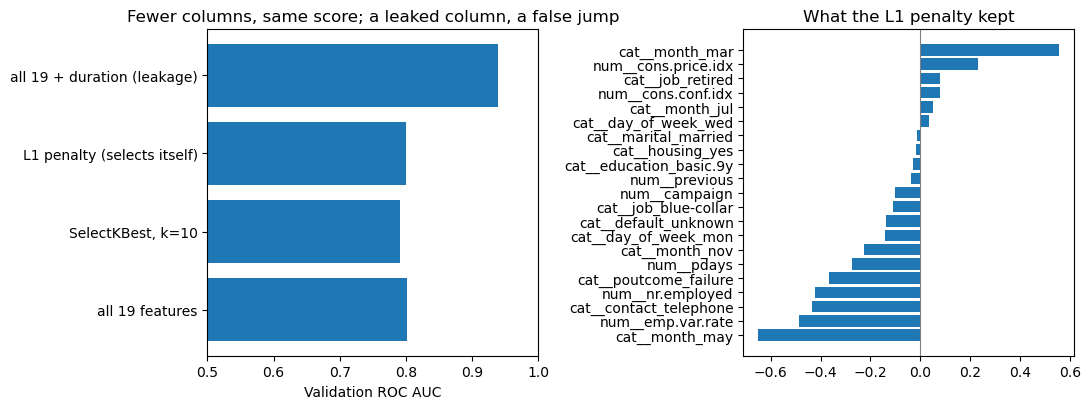

In [12]:
# One weight per encoded column; the L1 penalty set most of them to zero.
column_names = l1.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(l1.named_steps["model"].coef_[0], index=column_names)
kept = coefs[coefs != 0].sort_values()
print(f"the L1 penalty kept {len(kept)} of {len(coefs)} encoded columns")
strongest = kept.reindex(kept.abs().sort_values(ascending=False).index)
print(strongest.head(6).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh(list(results), list(results.values()))
axes[0].set_xlim(0.5, 1.0)
axes[0].set_xlabel("Validation ROC AUC")
axes[0].set_title("Fewer columns, same score; a leaked column, a false jump")
axes[1].barh(kept.index, kept.values)
axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_title("What the L1 penalty kept")
plt.tight_layout()
plt.savefig(RESULTS / "what_the_l1_penalty_kept.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** The file holds 12 duplicate rows; without them 41,176 calls remain, and 11.3% of them ended in a yes. 12,716 cells say `unknown`, and 96.3% of customers had never been called before. On the 19 columns known before the call, logistic regression scores ROC AUC 0.802. Ten selected columns score 0.791, and the L1 penalty, keeping 21 of 62 encoded columns, scores 0.801: two thirds of the encoded table can go. Adding `duration` lifts the score to 0.939. That looks like a triumph and is a broken experiment, because nobody knows how long a call will last before making it. The strongest survivors are the calendar and the economy: calls in May did worse and calls in March better, landline calls (`contact_telephone`) did worse than mobile ones, and a higher employment-variation rate and more people employed (`nr.employed`) went with fewer sign-ups. They describe this bank's campaigns of 2008 to 2010, not laws of banking.

**Checkpoint: before you move on**

- All 19 features score ROC AUC 0.802; adding `duration` jumps to 0.939, and that jump is leakage.
- The L1 penalty keeps 21 of the 62 encoded columns.

## Evidence

Write the numbers above to the results folder. These files are regenerated on every run; do not edit them by hand.

### Question 13 — Save the evidence

In [13]:
environment = pd.DataFrame({
    "package": ["numpy", "pandas", "matplotlib", "scikit-learn"],
    "version": [np.__version__, pd.__version__, matplotlib.__version__, sklearn.__version__],
})
environment.to_csv(RESULTS / "environment.csv", index=False)
missing.rename("share_missing").round(4).to_csv(RESULTS / "missing_values.csv")
by_lead.rename("cancellation_rate").round(3).rename_axis("days_ahead").to_csv(RESULTS / "cancellation_by_days_ahead.csv")
pd.Series(results, name="validation_roc_auc").rename_axis("feature_set").round(3).to_csv(RESULTS / "feature_selection.csv")
kept.rename("l1_coefficient").round(3).to_csv(RESULTS / "l1_coefficients.csv")

# The customer and both neighbor lists, in one table.
rows = np.r_[customer, near_raw, near_std]
neighbor_table = churn.loc[rows, ["customerID"] + money].copy()
neighbor_table["neighbors"] = ["the customer"] + ["raw units"] * 10 + ["standardized"] * 10
neighbor_table.to_csv(RESULTS / "neighbors_raw_and_scaled.csv", index=False)
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['cancellation_by_days_ahead.csv', 'environment.csv', 'far_ahead_bookings_cancel_most.png', 'feature_selection.csv', 'hotel_where_the_gaps_are.png', 'l1_coefficients.csv', 'missing_values.csv', 'neighbors_raw_and_scaled.csv', 'one_customer_two_sets_of_neighbors.png', 'what_the_l1_penalty_kept.png']


## Try it yourself

Engineer one more hotel feature, the weekday of arrival (from the `arrival_date` built in Question 3), and check whether the validation ROC AUC in Question 7 improves. Then rerun Question 11 with `k=5` and `k=20` and see whether the score changes.

Attempt it in the cell below before reading the solution.

### Question 14 — Try it yourself

In [14]:
# Your work here

### One solution

The arrival weekday for the hotel bookings, then the two other `k` values for the bank calls.

### Question 15 — One solution

In [15]:
# Part 1: the weekday of arrival, from the date built in Question 3.
hotels["arrival_weekday"] = hotels["arrival_date"].dt.day_name()
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print("cancellation rate by arrival day:", hotels.groupby("arrival_weekday")["is_canceled"].mean().reindex(days).round(3).to_dict())

num_cols, cat_cols = feature_sets["raw + engineered"]
for label, cats in {"raw + engineered": cat_cols, "raw + engineered + weekday": cat_cols + ["arrival_weekday"]}.items():
    X = hotels[num_cols + cats]
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
    model = Pipeline([
        ("preprocess", make_preprocess(num_cols, cats)),
        ("model", LogisticRegression(max_iter=3000)),
    ])
    model.fit(X_train, y_train)
    auc = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
    print(f"{label:26s} validation ROC AUC = {auc:.3f}")

# Part 2: other selection sizes for the bank calls.
for k in [5, 10, 20]:
    selected = Pipeline([
        ("preprocess", make_preprocess(b_num, b_cat)),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    evaluate(selected, Xb_train, Xb_valid, f"SelectKBest, k={k}")

cancellation rate by arrival day: {'Monday': 0.341, 'Tuesday': 0.329, 'Wednesday': 0.361, 'Thursday': 0.412, 'Friday': 0.406, 'Saturday': 0.395, 'Sunday': 0.323}


raw + engineered           validation ROC AUC = 0.855


raw + engineered + weekday validation ROC AUC = 0.856
SelectKBest, k=5             ROC AUC = 0.775   average precision = 0.419


SelectKBest, k=10            ROC AUC = 0.791   average precision = 0.435
SelectKBest, k=20            ROC AUC = 0.799   average precision = 0.442


**What it shows.** Arrivals on Thursday and Friday were cancelled most often (41.2% and 40.6%) and arrivals on Sunday least (32.3%), so the weekday carries real signal, yet validation ROC AUC only moves from 0.855 to 0.856. Much of what the weekday says is probably already in the columns the model has, such as the weekend and week nights. A feature can be informative and still add nothing, which is why the test is always the model's validation score, not the group table. For the bank calls, 5, 10 and 20 selected columns score 0.775, 0.791 and 0.799, against 0.802 for all of them: the score climbs slowly with `k`, and the exact number matters far less than keeping the selector inside the pipeline.